In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df=pd.read_csv(r"C:\Users\akars\OneDrive\Desktop\projects\End-to-End Supply Chain Analytics & Late Delivery Prediction\data\DataCoSupplyChainDataset_Cleaned.csv")

In [7]:

# Identify the order ID column
order_col = "Order_Id"

# Count total rows
total_rows = len(df)

# Count unique orders
unique_orders = df[order_col].nunique()

# Count rows belonging to repeated order IDs
repeated_order_rows = df.duplicated(
    subset=[order_col]
).sum()

print("Total rows:", total_rows)
print("Unique orders:", unique_orders)
print("Rows with previously seen order IDs:", repeated_order_rows)
print("Extra rows beyond one row per order:", total_rows - unique_orders)

Total rows: 180518
Unique orders: 65751
Rows with previously seen order IDs: 114767
Extra rows beyond one row per order: 114767


In [8]:

# Find order IDs that appear more than once
order_counts = (
    df["Order_Id"]
    .value_counts()
)

# Keep only repeated order IDs
repeated_orders = order_counts[order_counts > 1]

print("Number of order IDs appearing multiple times:",
      len(repeated_orders))

print("\nNumber of rows for the most frequent order IDs:")
display(repeated_orders.head(10).to_frame("Row_Count"))

# Inspect all rows for the most frequent order ID
if not repeated_orders.empty:
    sample_order_id = repeated_orders.index[0]

    print("\nInspecting order ID:", sample_order_id)

    display(
        df[df["Order_Id"] == sample_order_id].head(10)
    )

Number of order IDs appearing multiple times: 45902

Number of rows for the most frequent order IDs:


,Row_Count
Order_Id,
35170,5
63177,5
35475,5
35499,5
35523,5
31642,5
35655,5
35461,5
40518,5



Inspecting order ID: 35170


,Type,Days_for_shipping_(real),Days_for_shipment_(scheduled),Sales_per_customer,Delivery_Status,Late_delivery_risk,Category_Id,Category_Name,Customer_City,Customer_Country,...,Order_Region,Order_State,Order_Status,Product_Card_Id,Product_Category_Id,Product_Name,Product_Price,Product_Status,shipping_date_(DateOrders),Shipping_Mode
152370,CASH,6,2,399.980011,Late delivery,1,45,Fishing,Caguas,Puerto Rico,...,South of USA,Tennessee,CLOSED,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,2016-06-03,Second Class
173109,CASH,6,2,106.589996,Late delivery,1,18,Men's Footwear,Caguas,Puerto Rico,...,South of USA,Tennessee,CLOSED,403,18,Nike Men's CJ Elite 2 TD Football Cleat,129.990005,0,2016-06-03,Second Class
173117,CASH,6,2,272.980011,Late delivery,1,43,Camping & Hiking,Caguas,Puerto Rico,...,South of USA,Tennessee,CLOSED,957,43,Diamondback Women's Serene Classic Comfort Bi,299.980011,0,2016-06-03,Second Class
173238,CASH,6,2,176.369995,Late delivery,1,17,Cleats,Caguas,Puerto Rico,...,South of USA,Tennessee,CLOSED,365,17,Perfect Fitness Perfect Rip Deck,59.990002,0,2016-06-03,Second Class
173367,CASH,6,2,296.950012,Late delivery,1,17,Cleats,Caguas,Puerto Rico,...,South of USA,Tennessee,CLOSED,365,17,Perfect Fitness Perfect Rip Deck,59.990002,0,2016-06-03,Second Class


In [9]:
## Find the order-item ID column details

item_col = "Order_Item_Id"

print("Total rows:", len(df))
print("Unique order-item IDs:", df[item_col].nunique())
print("Missing order-item IDs:", df[item_col].isna().sum())
print("Duplicate order-item IDs:", df[item_col].duplicated().sum())

Total rows: 180518
Unique order-item IDs: 180518
Missing order-item IDs: 0
Duplicate order-item IDs: 0



Delivery status per item:


,Record_Count,Percentage
Delivery_Status,,
Late delivery,98977,54.83
Advance shipping,41591,23.04
Shipping on time,32196,17.84
Shipping canceled,7754,4.30


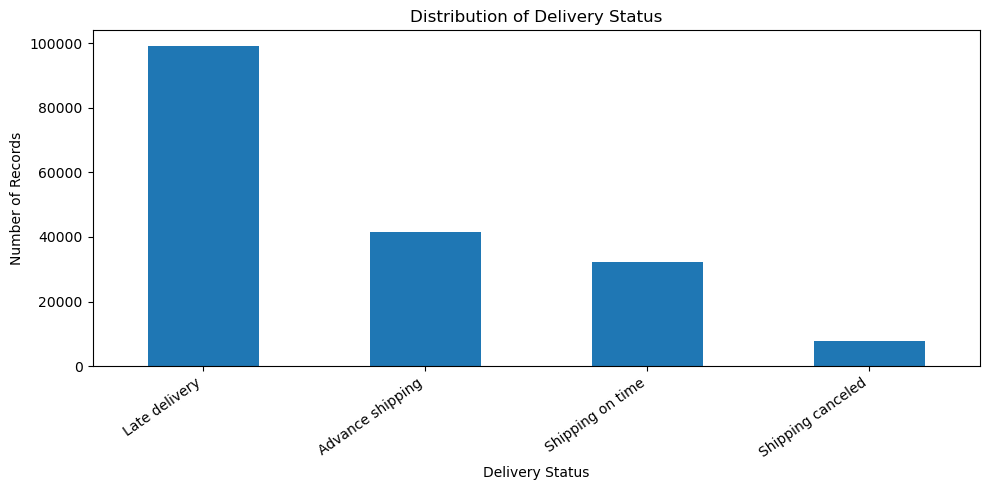

In [10]:
# Examine delivery status distribution
status_counts = df["Delivery_Status"].value_counts(
    dropna=False
)

# Calculate percentages
status_percentages = (
    df["Delivery_Status"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("\nDelivery status per item:")
display(status_counts.to_frame("Record_Count").join(status_percentages.to_frame("Percentage"), how="inner"))

# Visualize distribution
status_counts.plot(
    kind="bar",
    figsize=(10, 5),
    title="Distribution of Delivery Status"
)

plt.xlabel("Delivery Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [11]:
# Examine delivery status distribution

# Step 1: Count how many delivery statuses each order has
status_per_order = (
    df.groupby("Order_Id")["Delivery_Status"]
      .nunique()
)

print("Orders with multiple delivery statuses:",
      (status_per_order > 1).sum())

print("\nNumber of unique orders:", df["Order_Id"].nunique())


Orders with multiple delivery statuses: 0

Number of unique orders: 65751



Delivery status distribution by order:


,Order_Count,Percentage
Delivery_Status,,
Late delivery,36048,54.83
Advance shipping,15126,23.00
Shipping on time,11722,17.83
Shipping canceled,2855,4.34


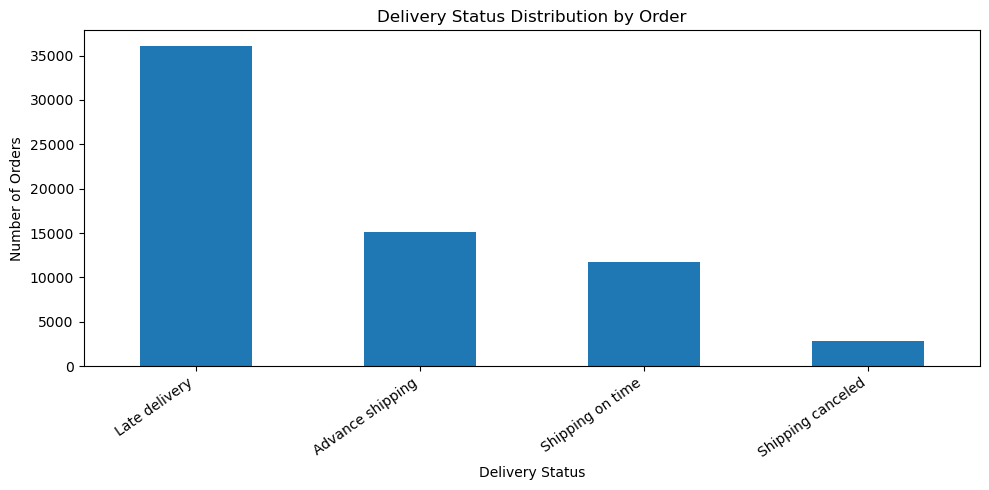

In [12]:
# Step 2: Create one row per order
orders_df = df.drop_duplicates(subset=["Order_Id"])

# Step 3: Count orders by delivery status
status_counts = orders_df["Delivery_Status"].value_counts(
    dropna=False
)

# Step 4: Calculate percentages
status_percentages = (
    orders_df["Delivery_Status"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

# Step 5: Display results
delivery_summary = pd.concat(
    [
        status_counts.rename("Order_Count"),
        status_percentages.rename("Percentage")
    ],
    axis=1
)

print("\nDelivery status distribution by order:")
display(delivery_summary)

# Step 6: Visualize
status_counts.plot(
    kind="bar",
    figsize=(10, 5),
    title="Delivery Status Distribution by Order"
)

plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Late-delivery performance by shipping mode:


,Total_Orders,Late_Orders,Late_Delivery_Rate
Shipping_Mode,,,
First Class,10079,9602,95.27
Second Class,12778,9803,76.72
Same Day,3571,1648,46.15
Standard Class,39323,14995,38.13


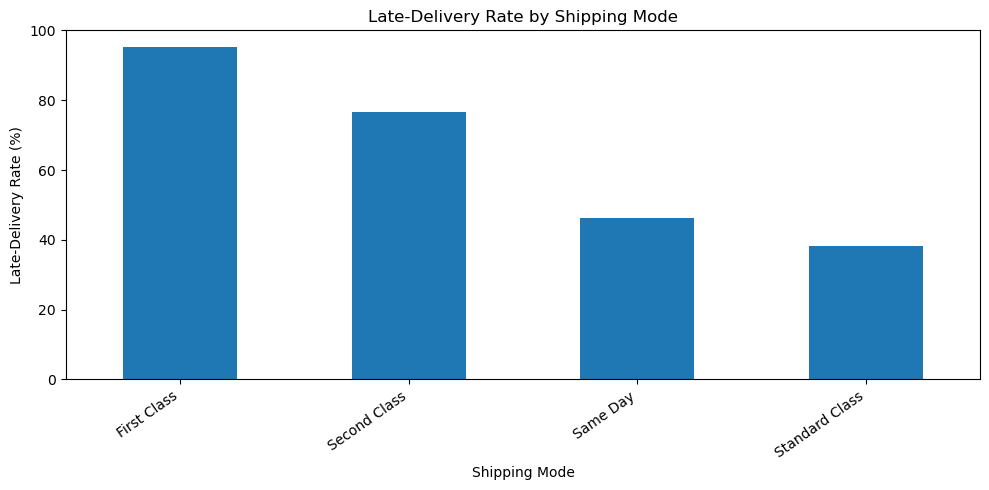

In [13]:
# Group orders by shipping mode
shipping_analysis = (
    orders_df.groupby("Shipping_Mode")
    .agg(
        Total_Orders=("Order_Id", "nunique"),
        Late_Orders=(
            "Delivery_Status",
            lambda x: (x == "Late delivery").sum()
        )
    )
)

# Calculate late-delivery percentage
shipping_analysis["Late_Delivery_Rate"] = (
    shipping_analysis["Late_Orders"]
    / shipping_analysis["Total_Orders"]
    * 100
).round(2)

# Sort from highest to lowest late-delivery rate
shipping_analysis = shipping_analysis.sort_values(
    by="Late_Delivery_Rate",
    ascending=False
)

print("Late-delivery performance by shipping mode:")
display(shipping_analysis)

# Visualize results
shipping_analysis["Late_Delivery_Rate"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Late-Delivery Rate by Shipping Mode"
)

plt.xlabel("Shipping Mode")
plt.ylabel("Late-Delivery Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [14]:
# Examine the delivery status distribution
print("Delivery status counts:")
display(df["Delivery_Status"].value_counts(dropna=False))

# Examine the delivery status by shipping mode
status_mode = pd.crosstab(
    df["Shipping_Mode"],
    df["Delivery_Status"],
    normalize="index"
).mul(100).round(2)

print("\nDelivery status percentages by shipping mode:")
display(status_mode)

Delivery status counts:


Delivery_Status
Late delivery        98977
Advance shipping     41591
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64


Delivery status percentages by shipping mode:


Delivery_Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Shipping_Mode,,,,
First Class,0.0,95.32,4.68,0.00
Same Day,0.0,45.74,4.56,49.70
Second Class,0.0,76.63,4.00,19.36
Standard Class,38.6,38.07,4.27,19.06


Delivery delay summary:


count    180518.000000
mean          0.565816
std           1.490966
min          -2.000000
25%           0.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: Delivery_Delay_Days, dtype: float64


Earlier than scheduled: 43365
Exactly on schedule: 33753
Later than scheduled: 103400


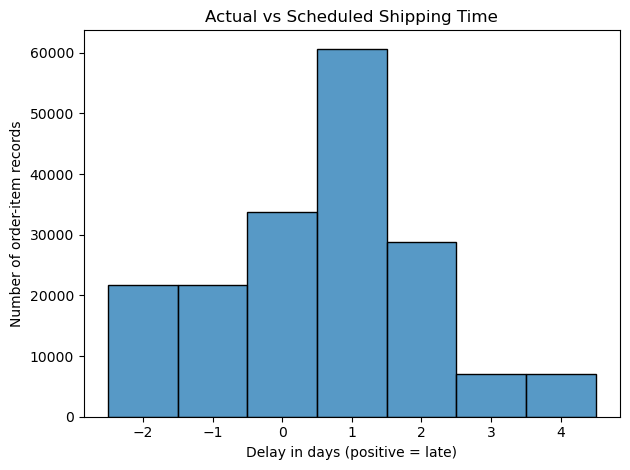

In [15]:
# Calculate the difference between actual and scheduled shipping days
actual_col = "Days_for_shipping_(real)"
scheduled_col = "Days_for_shipment_(scheduled)"

df["Delivery_Delay_Days"] = (
    df[actual_col] - df[scheduled_col]
)

# Summarize delivery performance
print("Delivery delay summary:")
display(df["Delivery_Delay_Days"].describe())

# Count each delivery outcome
early = (df["Delivery_Delay_Days"] < 0).sum()
on_schedule = (df["Delivery_Delay_Days"] == 0).sum()
late = (df["Delivery_Delay_Days"] > 0).sum()

print("\nEarlier than scheduled:", early)
print("Exactly on schedule:", on_schedule)
print("Later than scheduled:", late)

# Visualize the distribution
sns.histplot(
    data=df,
    x="Delivery_Delay_Days",
    discrete=True
)

plt.title("Actual vs Scheduled Shipping Time")
plt.xlabel("Delay in days (positive = late)")
plt.ylabel("Number of order-item records")
plt.tight_layout()
plt.show()

,Total_Records,Average_Actual_Days,Average_Scheduled_Days,Average_Delay_Days
Shipping_Mode,,,,
Second Class,35216,3.99,2.0,1.99
First Class,27814,2.00,1.0,1.00
Same Day,9737,0.48,0.0,0.48
Standard Class,107751,4.00,4.0,-0.00


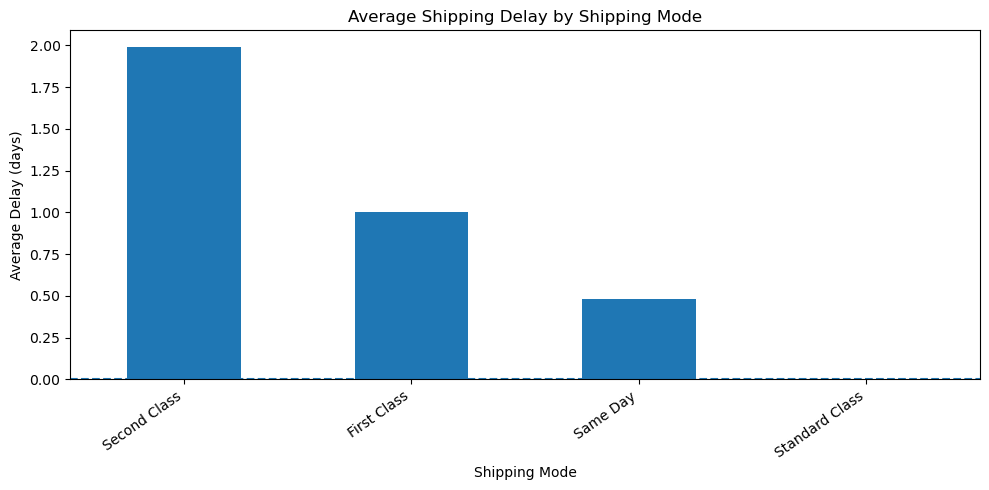

In [16]:
# Compare actual and scheduled shipping durations by mode
shipping_delay = (
    df.groupby("Shipping_Mode")
    .agg(
        Total_Records=("Order_Id", "size"),
        Average_Actual_Days=("Days_for_shipping_(real)", "mean"),
        Average_Scheduled_Days=(
            "Days_for_shipment_(scheduled)", "mean"
        ),
        Average_Delay_Days=("Delivery_Delay_Days", "mean")
    )
    .round(2)
    .sort_values("Average_Delay_Days", ascending=False)
)

display(shipping_delay)

# Visualize average delay
shipping_delay["Average_Delay_Days"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Shipping Delay by Shipping Mode"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Delay (days)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

,Total_Records,Average_Delay_Days,Late_Records,Late_Percentage
Order_Region,,,,
Central Asia,553,0.65,316,57.14
Central Africa,1677,0.64,1018,60.70
South Asia,7731,0.60,4523,58.50
Western Europe,27109,0.60,15863,58.52
US Center,5887,0.59,3363,57.13
East of USA,6915,0.58,4009,57.98
South of USA,4045,0.58,2350,58.10
Eastern Europe,3920,0.58,2252,57.45
East Africa,1852,0.57,1064,57.45


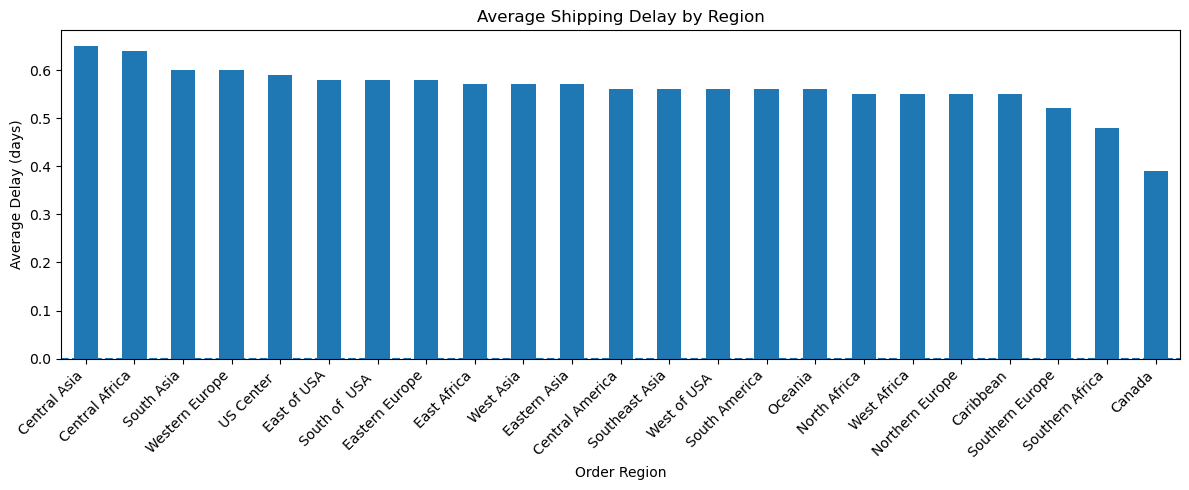

In [17]:
# Analyze shipping delay by region
region_delay = (
    df.groupby("Order_Region")
    .agg(
        Total_Records=("Order_Id", "size"),
        Average_Delay_Days=("Delivery_Delay_Days", "mean"),
        Late_Records=("Delivery_Delay_Days", lambda x: (x > 0).sum())
    )
)

# Calculate the percentage of records delayed
region_delay["Late_Percentage"] = (
    region_delay["Late_Records"]
    / region_delay["Total_Records"]
    * 100
).round(2)

# Sort by average delay
region_delay = region_delay.sort_values(
    "Average_Delay_Days",
    ascending=False
).round(2)

display(region_delay)

# Plot average delay by region
region_delay["Average_Delay_Days"].plot(
    kind="bar",
    figsize=(12, 5),
    title="Average Shipping Delay by Region"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Order Region")
plt.ylabel("Average Delay (days)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [18]:
# Analyze delay by region AND shipping mode
region_mode_delay = (
    df.groupby(["Order_Region", "Shipping_Mode"])
    .agg(
        Total_Records=("Order_Id", "size"),
        Average_Delay=("Delivery_Delay_Days", "mean"),
        Late_Records=(
            "Delivery_Delay_Days",
            lambda x: (x > 0).sum()
        )
    )
)

# Calculate late percentage
region_mode_delay["Late_Percentage"] = (
    region_mode_delay["Late_Records"]
    / region_mode_delay["Total_Records"]
    * 100
)

# Sort by average delay
region_mode_delay = region_mode_delay.sort_values(
    "Average_Delay", ascending=False
).round(2)

display(region_mode_delay)

,,Total_Records,Average_Delay,Late_Records,Late_Percentage
Order_Region,Shipping_Mode,,,,
Central Asia,Second Class,117,2.21,106,90.60
Central Africa,Second Class,297,2.13,245,82.49
Eastern Asia,Second Class,1406,2.12,1178,83.78
Western Europe,Second Class,5438,2.06,4412,81.13
South Asia,Second Class,1552,2.04,1240,79.90
...,...,...,...,...,...
Eastern Asia,Standard Class,4425,-0.02,1712,38.69
West of USA,Standard Class,4787,-0.03,1853,38.71
Caribbean,Standard Class,5043,-0.04,1878,37.24


In [19]:
# Validate late delivery rates by shipping mode
mode_validation = (
    df.groupby("Shipping_Mode")
    .agg(
        Total_Records=("Order_Id", "size"),
        Late_Records=(
            "Delivery_Status",
            lambda x: (x == "Late delivery").sum()
        ),
        Average_Actual_Days=(
            "Days_for_shipping_(real)", "mean"
        ),
        Average_Scheduled_Days=(
            "Days_for_shipment_(scheduled)", "mean"
        )
    )
)

mode_validation["Late_Percentage"] = (
    mode_validation["Late_Records"]
    / mode_validation["Total_Records"]
    * 100
).round(2)

mode_validation = mode_validation.sort_values(
    "Late_Percentage", ascending=False
).round(2)

display(mode_validation)

,Total_Records,Late_Records,Average_Actual_Days,Average_Scheduled_Days,Late_Percentage
Shipping_Mode,,,,,
First Class,27814,26513,2.00,1.0,95.32
Second Class,35216,26987,3.99,2.0,76.63
Same Day,9737,4454,0.48,0.0,45.74
Standard Class,107751,41023,4.00,4.0,38.07


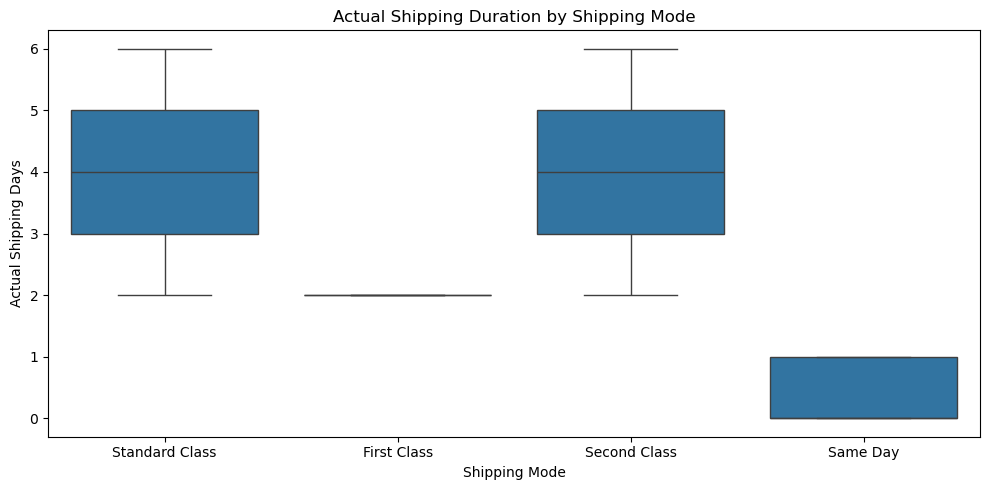

,Actual_Min,Actual_Median,Actual_Max,Scheduled_Days
Shipping_Mode,,,,
First Class,2,2.0,2,1.0
Same Day,0,0.0,1,0.0
Second Class,2,4.0,6,2.0
Standard Class,2,4.0,6,4.0


In [20]:
# Distribution of actual shipping duration by shipping mode
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Shipping_Mode",
    y="Days_for_shipping_(real)"
)

plt.title("Actual Shipping Duration by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Actual Shipping Days")
plt.tight_layout()
plt.show()

# Compare actual vs scheduled durations
duration_comparison = (
    df.groupby("Shipping_Mode")
    .agg(
        Actual_Min=("Days_for_shipping_(real)", "min"),
        Actual_Median=("Days_for_shipping_(real)", "median"),
        Actual_Max=("Days_for_shipping_(real)", "max"),
        Scheduled_Days=(
            "Days_for_shipment_(scheduled)", "median"
        )
    )
)

display(duration_comparison)

,Total_Records,Canceled_Records,Cancellation_Rate
Shipping_Mode,,,
First Class,27814,1301,4.68
Same Day,9737,444,4.56
Standard Class,107751,4599,4.27
Second Class,35216,1410,4.00


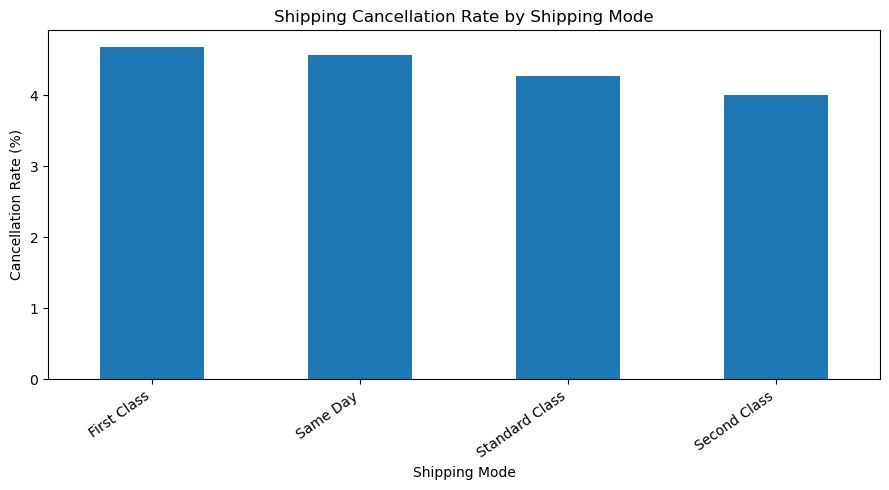

In [21]:
# Analyze cancellations by shipping mode
cancellation_analysis = (
    df.groupby("Shipping_Mode")
    .agg(
        Total_Records=("Order_Id", "size"),
        Canceled_Records=(
            "Delivery_Status",
            lambda x: (x == "Shipping canceled").sum()
        )
    )
)

# Calculate cancellation percentage
cancellation_analysis["Cancellation_Rate"] = (
    cancellation_analysis["Canceled_Records"]
    / cancellation_analysis["Total_Records"]
    * 100
).round(2)

# Sort by cancellation rate
cancellation_analysis = cancellation_analysis.sort_values(
    "Cancellation_Rate",
    ascending=False
)

display(cancellation_analysis)

# Plot cancellation rates
cancellation_analysis["Cancellation_Rate"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Shipping Cancellation Rate by Shipping Mode"
)

plt.xlabel("Shipping Mode")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

,Total_Records,Canceled_Records,Cancellation_Rate
Order_Region,,,
Canada,959,52,5.42
South America,14935,751,5.03
West of USA,7993,398,4.98
Southern Africa,1157,57,4.93
South of USA,4045,190,4.70
Western Europe,27109,1242,4.58
North Africa,3232,146,4.52
Caribbean,8318,367,4.41
West Asia,6009,263,4.38


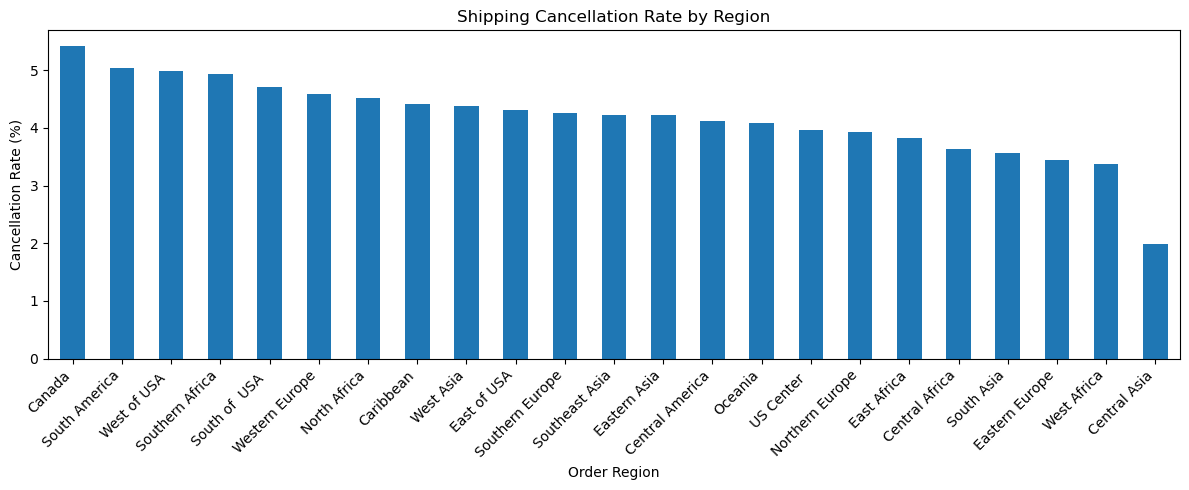

In [22]:
# Analyze cancellations by region
region_cancellations = (
    df.groupby("Order_Region")
    .agg(
        Total_Records=("Order_Id", "size"),
        Canceled_Records=(
            "Delivery_Status",
            lambda x: (x == "Shipping canceled").sum()
        )
    )
)

# Calculate cancellation rate
region_cancellations["Cancellation_Rate"] = (
    region_cancellations["Canceled_Records"]
    / region_cancellations["Total_Records"]
    * 100
).round(2)

# Sort from highest to lowest cancellation rate
region_cancellations = region_cancellations.sort_values(
    "Cancellation_Rate",
    ascending=False
)

display(region_cancellations)

# Visualize cancellation rates
region_cancellations["Cancellation_Rate"].plot(
    kind="bar",
    figsize=(12, 5),
    title="Shipping Cancellation Rate by Region"
)

plt.xlabel("Order Region")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [23]:
# Analyze cancellations by region and shipping mode
region_mode_cancellations = (
    df.groupby(["Order_Region", "Shipping_Mode"])
    .agg(
        Total_Records=("Order_Id", "size"),
        Canceled_Records=(
            "Delivery_Status",
            lambda x: (x == "Shipping canceled").sum()
        )
    )
)

# Calculate cancellation rate
region_mode_cancellations["Cancellation_Rate"] = (
    region_mode_cancellations["Canceled_Records"]
    / region_mode_cancellations["Total_Records"]
    * 100
).round(2)

# Show the 15 combinations with the highest rates
region_mode_cancellations = region_mode_cancellations.sort_values(
    "Cancellation_Rate",
    ascending=False
)

display(region_mode_cancellations.head(25))

,,Total_Records,Canceled_Records,Cancellation_Rate
Order_Region,Shipping_Mode,,,
Southern Africa,Same Day,75,12,16.00
Canada,Same Day,33,4,12.12
South of USA,Same Day,235,18,7.66
Canada,First Class,184,14,7.61
Central Africa,First Class,300,22,7.33
Southern Africa,Second Class,150,11,7.33
Canada,Second Class,166,12,7.23
Oceania,First Class,1366,96,7.03
South America,First Class,2311,157,6.79


Shipping_Mode,First Class,Same Day,Second Class,Standard Class
Order_Region,,,,
Canada,7.61,12.12,7.23,3.82
Caribbean,5.11,5.10,5.09,3.97
Central Africa,7.33,0.00,2.02,3.30
Central America,4.50,4.64,4.21,3.95
Central Asia,0.00,0.00,4.27,1.94
East Africa,1.07,3.06,2.49,5.04
East of USA,3.58,5.02,4.38,4.41
Eastern Asia,5.18,3.69,4.62,3.91
Eastern Europe,3.95,1.12,2.20,3.89


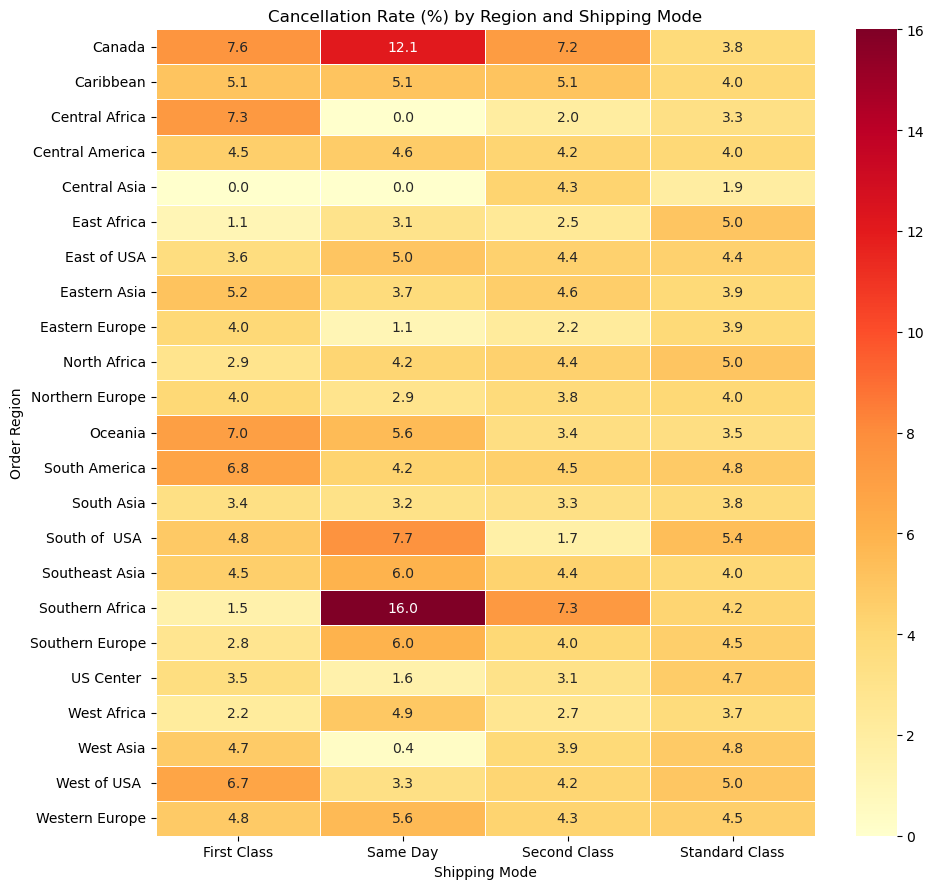

In [24]:
# Create a region vs shipping-mode cancellation-rate table
cancellation_pivot = pd.pivot_table(
    df.assign(
        Is_Canceled=(
            df["Delivery_Status"] == "Shipping canceled"
        ).astype(int)
    ),
    index="Order_Region",
    columns="Shipping_Mode",
    values="Is_Canceled",
    aggfunc="mean"
) * 100

cancellation_pivot = cancellation_pivot.round(2)

display(cancellation_pivot)

# Visualize the pattern
plt.figure(figsize=(10, 9))

sns.heatmap(
    cancellation_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Cancellation Rate (%) by Region and Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Order Region")
plt.tight_layout()
plt.show()

In [25]:
# Build a combined logistics performance summary
logistics_summary = (
    df.groupby("Shipping_Mode")
    .agg(
        Total_Records=("Order_Id", "size"),
        Late_Records=(
            "Delivery_Status",
            lambda x: (x == "Late delivery").sum()
        ),
        Canceled_Records=(
            "Delivery_Status",
            lambda x: (x == "Shipping canceled").sum()
        ),
        Average_Delay_Days=("Delivery_Delay_Days", "mean")
    )
)

# Calculate rates
logistics_summary["Late_Rate_Percent"] = (
    logistics_summary["Late_Records"]
    / logistics_summary["Total_Records"] * 100
)

logistics_summary["Cancellation_Rate_Percent"] = (
    logistics_summary["Canceled_Records"]
    / logistics_summary["Total_Records"] * 100
)

# Round results
logistics_summary = logistics_summary.round(2)

# Rank by late-delivery rate
logistics_summary = logistics_summary.sort_values(
    "Late_Rate_Percent",
    ascending=False
)

display(logistics_summary)

,Total_Records,Late_Records,Canceled_Records,Average_Delay_Days,Late_Rate_Percent,Cancellation_Rate_Percent
Shipping_Mode,,,,,,
First Class,27814,26513,1301,1.00,95.32,4.68
Second Class,35216,26987,1410,1.99,76.63,4.00
Same Day,9737,4454,444,0.48,45.74,4.56
Standard Class,107751,41023,4599,-0.00,38.07,4.27


In [26]:
# Identify date-related columns
for col in df.columns:
    if "date" in col.lower():
        print(col, ":", df[col].dtype)

order_date_(DateOrders) : object
shipping_date_(DateOrders) : object


In [27]:
# Convert order date to datetime
df["order_date_(DateOrders)"] = pd.to_datetime(
    df["order_date_(DateOrders)"],
    errors="coerce"
)

# Extract year and month
df["Order_Year"] = df["order_date_(DateOrders)"].dt.year
df["Order_Month"] = df["order_date_(DateOrders)"].dt.month

# Analyze monthly delivery performance
monthly_delivery = (
    df.groupby(["Order_Year", "Order_Month"])
    .agg(
        Total_Records=("Order_Id", "size"),
        Late_Records=(
            "Delivery_Status",
            lambda x: (x == "Late delivery").sum()
        )
    )
)

# Calculate late-delivery percentage
monthly_delivery["Late_Rate_Percent"] = (
    monthly_delivery["Late_Records"]
    / monthly_delivery["Total_Records"]
    * 100
).round(2)

display(monthly_delivery)

Total_Records  Late_Records  Late_Rate_Percent
Order_Year Order_Month                                                
2015       1                     5322          2880              54.11
           2                     4729          2594              54.85
           3                     5362          2936              54.76
           4                     5126          2760              53.84
           5                     5357          2951              55.09
           6                     5134          2778              54.11
           7                     5299          2939              55.46
           8                     5273          2936              55.68
           9                     5140          2914              56.69
           10                    5302          2906              54.81
           11                    5235          2841              54.27
           12                    5371          2937              54.68
2016       1                     5317          2955              55.58
           2                     4894          2650              54.15
           3                     5210          2905              55.76
           4                     5097          2815              55.23
           5                     5302          2951              55.66
           6                     5054          2873              56.85
           7                     5305          2755              51.93
           8                     5334          2948              55.27
           9                     5160          2837              54.98
           10                    5398          2957              54.78
           11                    5210          2846              54.63
           12                    5269          2954              56.06
2017       1                     5217          2797              53.61
           2                     4906          2682              54.67
           3                     5347          2955              55.26
           4                     5212          2803              53.78
           5                     5317          2843              53.47
           6                     4951          2649              53.50
           7                     5318          2913              54.78
           8                     5305          2994              56.44
           9                     5189          2814              54.23
           10                    2255          1210              53.66
           11                    2055          1132              55.09
           12                    2124          1172              55.18
2018       1                     2122          1195              56.31

In [28]:
# Convert the MultiIndex into normal columns
monthly_delivery = monthly_delivery.reset_index()

# Convert month number into month name
monthly_delivery["Month_Name"] = pd.to_datetime(
    monthly_delivery["Order_Month"],
    format="%m"
).dt.month_name()

# Display year and month as separate columns
display(
    monthly_delivery[
        [
            "Order_Year",
            "Order_Month",
            "Month_Name",
            "Total_Records",
            "Late_Records",
            "Late_Rate_Percent"
        ]
    ]
)


,Order_Year,Order_Month,Month_Name,Total_Records,Late_Records,Late_Rate_Percent
0,2015,1,January,5322,2880,54.11
1,2015,2,February,4729,2594,54.85
2,2015,3,March,5362,2936,54.76
3,2015,4,April,5126,2760,53.84
4,2015,5,May,5357,2951,55.09
5,2015,6,June,5134,2778,54.11
6,2015,7,July,5299,2939,55.46
7,2015,8,August,5273,2936,55.68
8,2015,9,September,5140,2914,56.69
9,2015,10,October,5302,2906,54.81


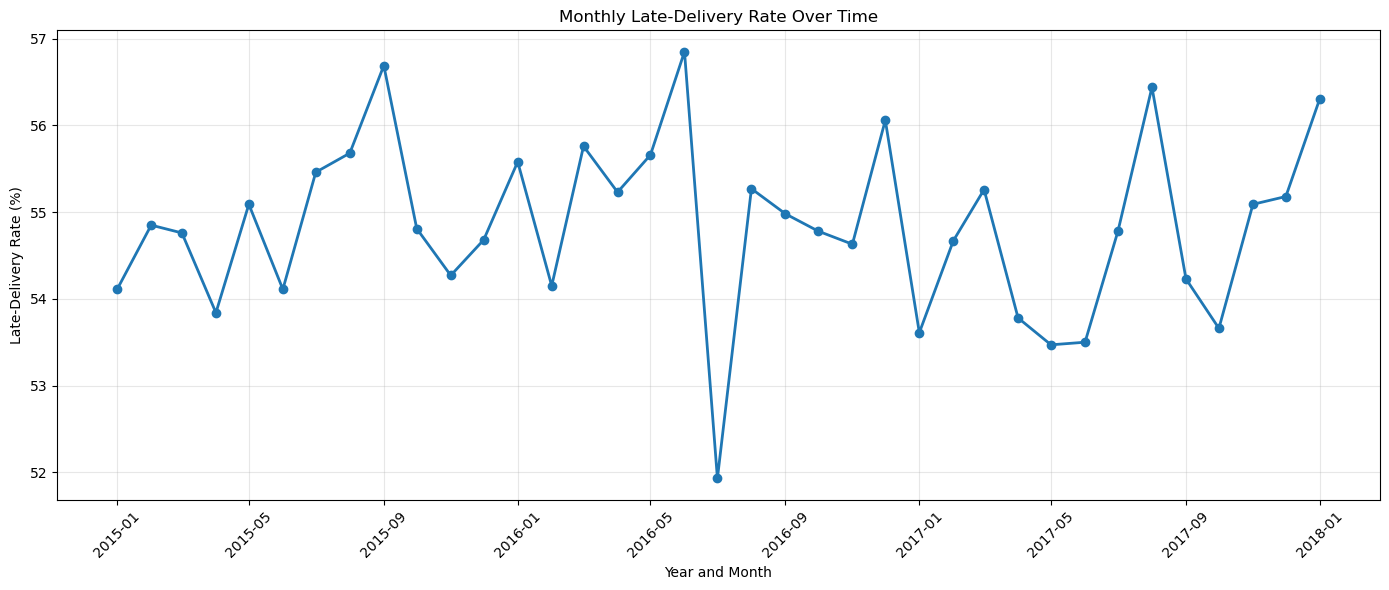

In [29]:
# Create a combined Year-Month column
monthly_delivery["Year_Month"] = pd.to_datetime(
    monthly_delivery["Order_Year"].astype(str)
    + "-"
    + monthly_delivery["Order_Month"].astype(str).str.zfill(2)
    + "-01"
)

# Sort chronologically
monthly_delivery = monthly_delivery.sort_values("Year_Month")

# Plot year and month together
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_delivery["Year_Month"],
    monthly_delivery["Late_Rate_Percent"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Late-Delivery Rate Over Time")
plt.xlabel("Year and Month")
plt.ylabel("Late-Delivery Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

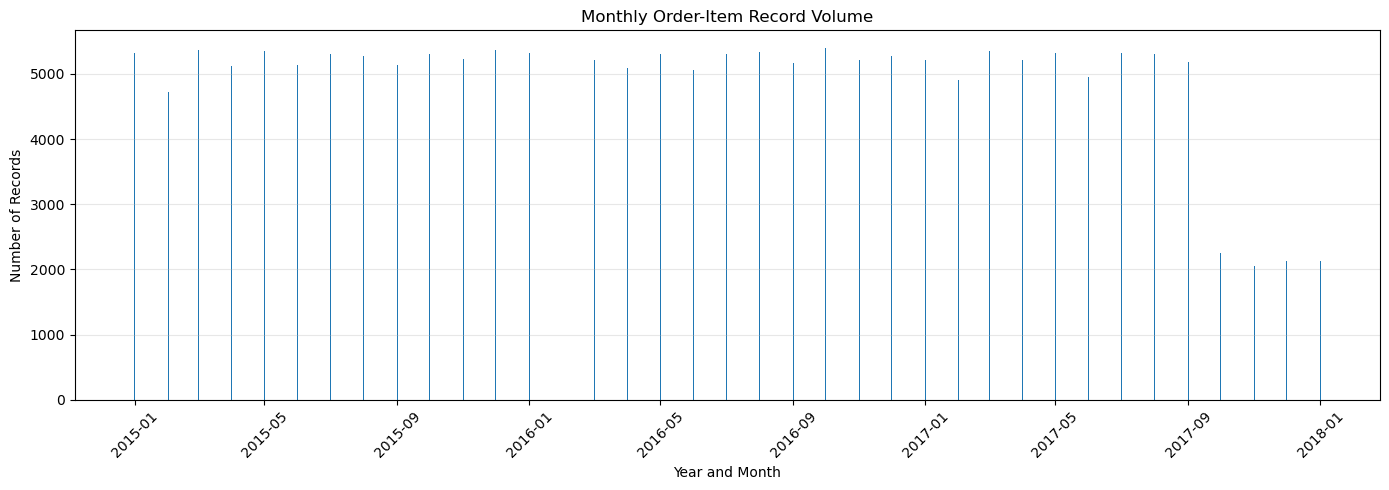

In [30]:

plt.figure(figsize=(14, 5))

plt.bar(
    monthly_delivery["Year_Month"],
    monthly_delivery["Total_Records"]
)

plt.title("Monthly Order-Item Record Volume")
plt.xlabel("Year and Month")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:

market_analysis = (
    df.groupby("Market")
    .agg(
        Total_Records=("Order_Item_Id", "count"),
        Late_Records=(
            "Delivery_Status",
            lambda x: (x == "Late delivery").sum()
        ),
        Cancelled_Records=(
            "Delivery_Status",
            lambda x: (x == "Shipping canceled").sum()
        )
    )
    .reset_index()
)

market_analysis["Late_Rate_Percent"] = (
    market_analysis["Late_Records"]
    / market_analysis["Total_Records"] * 100
).round(2)

market_analysis["Cancellation_Rate_Percent"] = (
    market_analysis["Cancelled_Records"]
    / market_analysis["Total_Records"] * 100
).round(2)

market_analysis = market_analysis.sort_values(
    "Late_Rate_Percent", ascending=False
)

display(market_analysis)

,Market,Total_Records,Late_Records,Cancelled_Records,Late_Rate_Percent,Cancellation_Rate_Percent
1,Europe,50252,27743,2162,55.21,4.30
3,Pacific Asia,41259,22712,1675,55.05,4.06
4,USCA,25799,14138,1172,54.80,4.54
0,Africa,11614,6340,460,54.59,3.96
2,LATAM,51594,28044,2285,54.36,4.43


In [32]:
market_shipping = (
    df.groupby(["Market", "Shipping_Mode"])
    .agg(
        Total_Records=("Order_Item_Id", "count"),
        Late_Records=(
            "Delivery_Status",
            lambda x: (x == "Late delivery").sum()
        ),
        Cancelled_Records=(
            "Delivery_Status",
            lambda x: (x == "Shipping canceled").sum()
        )
    )
    .reset_index()
)

market_shipping["Late_Rate_Percent"] = (
    market_shipping["Late_Records"]
    / market_shipping["Total_Records"] * 100
).round(2)

market_shipping["Cancellation_Rate_Percent"] = (
    market_shipping["Cancelled_Records"]
    / market_shipping["Total_Records"] * 100
).round(2)

display(
    market_shipping.sort_values(
        "Late_Rate_Percent",
        ascending=False
    )
)

,Market,Shipping_Mode,Total_Records,Late_Records,Cancelled_Records,Late_Rate_Percent,Cancellation_Rate_Percent
0,Africa,First Class,1727,1675,52,96.99,3.01
4,Europe,First Class,7892,7562,330,95.82,4.18
16,USCA,First Class,4008,3814,194,95.16,4.84
12,Pacific Asia,First Class,6301,5991,310,95.08,4.92
8,LATAM,First Class,7886,7471,415,94.74,5.26
2,Africa,Second Class,2164,1675,73,77.40,3.37
14,Pacific Asia,Second Class,8147,6293,318,77.24,3.90
6,Europe,Second Class,9861,7596,391,77.03,3.97
18,USCA,Second Class,5105,3913,187,76.65,3.66
10,LATAM,Second Class,9939,7510,441,75.56,4.44


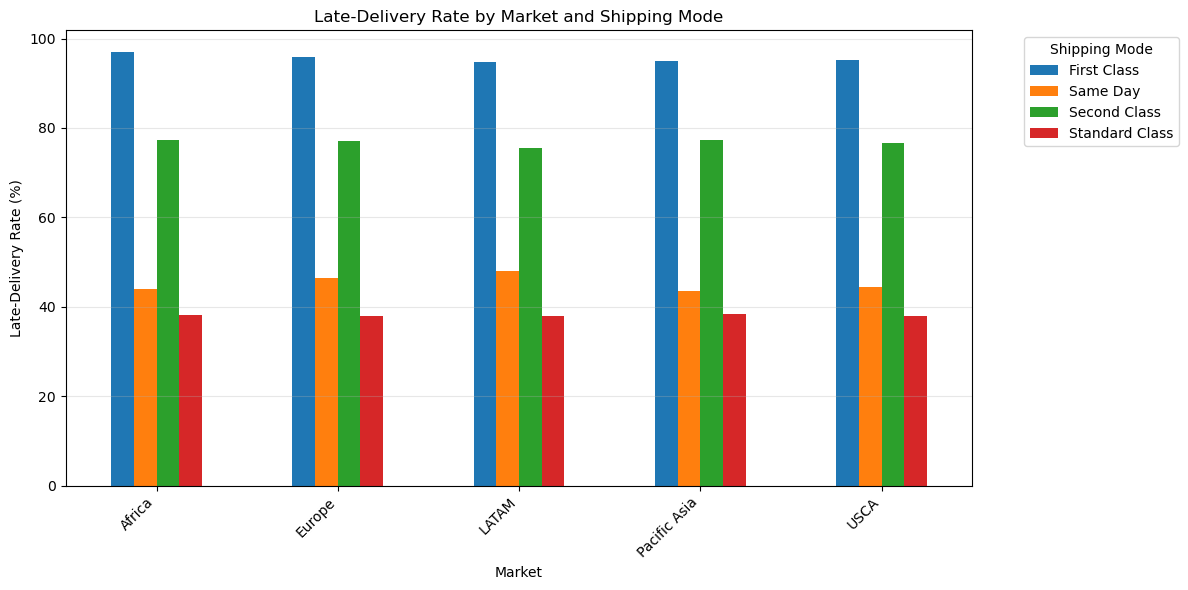

In [33]:

pivot_late = market_shipping.pivot(
    index="Market",
    columns="Shipping_Mode",
    values="Late_Rate_Percent"
)

pivot_late.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Late-Delivery Rate by Market and Shipping Mode")
plt.xlabel("Market")
plt.ylabel("Late-Delivery Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Shipping Mode", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [34]:
shipping_time_analysis = (
    df.groupby("Shipping_Mode")
    .agg(
        Total_Records=("Order_Item_Id", "count"),
        Avg_Actual_Days=("Days_for_shipping_(real)", "mean"),
        Avg_Scheduled_Days=("Days_for_shipment_(scheduled)", "mean"),
        Avg_Delay_Days=("Delivery_Delay_Days", "mean")
    )
    .round(2)
    .reset_index()
)

display(
    shipping_time_analysis.sort_values(
        "Avg_Delay_Days",
        ascending=False
    )
)

,Shipping_Mode,Total_Records,Avg_Actual_Days,Avg_Scheduled_Days,Avg_Delay_Days
2,Second Class,35216,3.99,2.0,1.99
0,First Class,27814,2.00,1.0,1.00
1,Same Day,9737,0.48,0.0,0.48
3,Standard Class,107751,4.00,4.0,-0.00


In [35]:

df["Order_Item_Id"].count()
df["Customer_Segment"].value_counts()

Customer_Segment
Consumer       93503
Corporate      54789
Home Office    32226
Name: count, dtype: int64

In [36]:
priority_analysis = (
    df.groupby("Customer_Segment")
    .agg(
        Total_Records=("Order_Item_Id", "count"),
        Late_Records=(
            "Delivery_Status",
            lambda x: (x == "Late delivery").sum()
        ),
        Cancelled_Records=(
            "Delivery_Status",
            lambda x: (x == "Shipping canceled").sum()
        )
    )
    .reset_index()
)

priority_analysis["Late_Rate_Percent"] = (
    priority_analysis["Late_Records"]
    / priority_analysis["Total_Records"] * 100
).round(2)

priority_analysis["Cancellation_Rate_Percent"] = (
    priority_analysis["Cancelled_Records"]
    / priority_analysis["Total_Records"] * 100
).round(2)

display(
    priority_analysis.sort_values(
        "Late_Rate_Percent",
        ascending=False
    )
)

,Customer_Segment,Total_Records,Late_Records,Cancelled_Records,Late_Rate_Percent,Cancellation_Rate_Percent
2,Home Office,32226,17747,1409,55.07,4.37
0,Consumer,93503,51248,4084,54.81,4.37
1,Corporate,54789,29982,2261,54.72,4.13


In [37]:

category_delivery = (
    df.groupby("Category_Name")
    .agg(
        Total_Records=("Order_Item_Id", "count"),
        Late_Records=(
            "Delivery_Status",
            lambda x: (x == "Late delivery").sum()
        ),
        Cancelled_Records=(
            "Delivery_Status",
            lambda x: (x == "Shipping canceled").sum()
        )
    )
    .reset_index()
)

category_delivery["Late_Rate_Percent"] = (
    category_delivery["Late_Records"]
    / category_delivery["Total_Records"] * 100
).round(2)

category_delivery["Cancellation_Rate_Percent"] = (
    category_delivery["Cancelled_Records"]
    / category_delivery["Total_Records"] * 100
).round(2)

display(
    category_delivery.sort_values(
        "Late_Rate_Percent",
        ascending=False
    )
)

,Category_Name,Total_Records,Late_Records,Cancelled_Records,Late_Rate_Percent,Cancellation_Rate_Percent
23,Golf Bags & Carts,61,42,0,68.85,0.00
32,Lacrosse,343,206,14,60.06,4.08
37,Pet Supplies,492,290,20,58.94,4.07
8,Cameras,592,344,30,58.11,5.07
41,Strength Training,111,64,2,57.66,1.80
1,As Seen on TV!,68,39,2,57.35,2.94
36,Music,434,248,17,57.14,3.92
0,Accessories,1780,1014,83,56.97,4.66
19,Fitness Accessories,309,176,13,56.96,4.21
5,Books,405,229,14,56.54,3.46


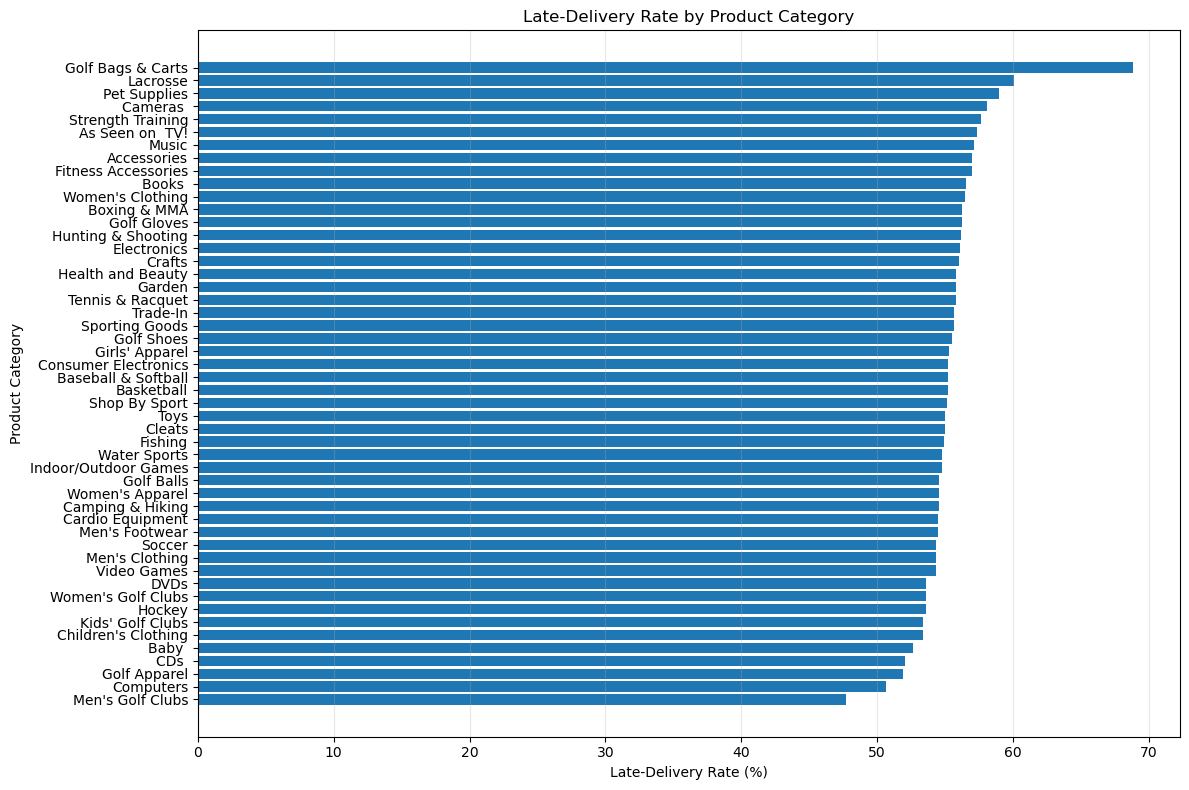

In [38]:


category_plot = category_delivery.sort_values(
    "Late_Rate_Percent",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    category_plot["Category_Name"],
    category_plot["Late_Rate_Percent"]
)

plt.title("Late-Delivery Rate by Product Category")
plt.xlabel("Late-Delivery Rate (%)")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

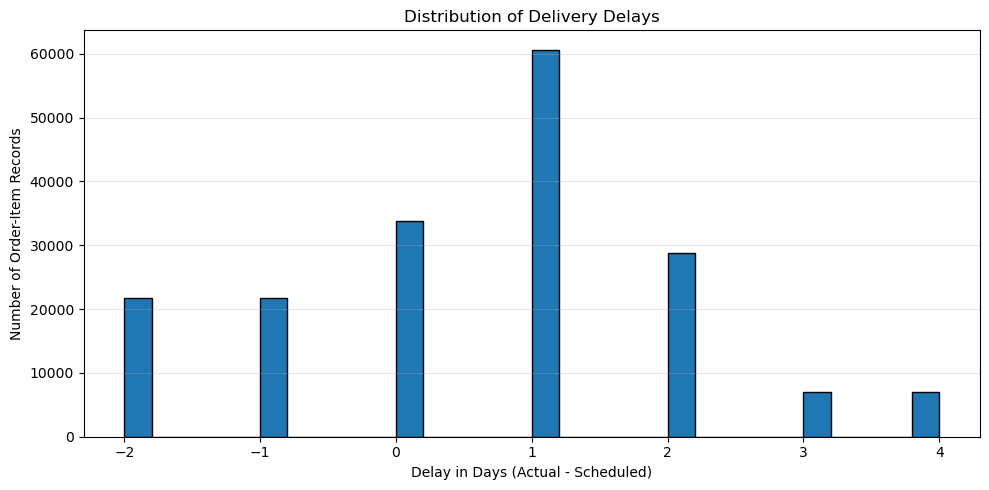

In [39]:


plt.figure(figsize=(10, 5))

plt.hist(
    df["Delivery_Delay_Days"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Delivery Delays")
plt.xlabel("Delay in Days (Actual - Scheduled)")
plt.ylabel("Number of Order-Item Records")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:

Q1 = df["Delivery_Delay_Days"].quantile(0.25)
Q3 = df["Delivery_Delay_Days"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Delivery_Delay_Days"] < lower_bound) |
    (df["Delivery_Delay_Days"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outlier records:", len(outliers))
print(
    "Percentage of records:",
    round(len(outliers) / len(df) * 100, 2), "%"
)

Q1: 0.0
Q3: 1.0
IQR: 1.0
Lower bound: -1.5
Upper bound: 2.5
Potential outlier records: 35701
Percentage of records: 19.78 %


In [41]:

early_outliers = df[
    df["Delivery_Delay_Days"] < lower_bound
]

late_outliers = df[
    df["Delivery_Delay_Days"] > upper_bound
]

print("Early-delivery outliers:", len(early_outliers))
print("Extreme-delay outliers:", len(late_outliers))

print(
    "Early outliers (%):",
    round(len(early_outliers) / len(df) * 100, 2)
)

print(
    "Extreme-delay outliers (%):",
    round(len(late_outliers) / len(df) * 100, 2)
)

Early-delivery outliers: 21666
Extreme-delay outliers: 14035
Early outliers (%): 12.0
Extreme-delay outliers (%): 7.77


In [42]:

df.nlargest(
    20, "Delivery_Delay_Days"
)[
    [
        "Order_Id",
        "Shipping_Mode",
        "Delivery_Status",
        "Days_for_shipping_(real)",
        "Days_for_shipment_(scheduled)",
        "Delivery_Delay_Days"
    ]
]

,Order_Id,Shipping_Mode,Delivery_Status,Days_for_shipping_(real),Days_for_shipment_(scheduled),Delivery_Delay_Days
9,75930,Second Class,Shipping canceled,6,2,4
24,75915,Second Class,Late delivery,6,2,4
49,31115,Second Class,Late delivery,6,2,4
53,20365,Second Class,Late delivery,6,2,4
56,32090,Second Class,Late delivery,6,2,4
64,65030,Second Class,Late delivery,6,2,4
72,12525,Second Class,Late delivery,6,2,4
73,5895,Second Class,Late delivery,6,2,4
85,55155,Second Class,Late delivery,6,2,4
136,51050,Second Class,Late delivery,6,2,4


In [43]:

print("Maximum delay:", df["Delivery_Delay_Days"].max())

print("\nRecords with a 4-day delay:")
print((df["Delivery_Delay_Days"] == 4).sum())

print("\nStatus breakdown for 4-day delays:")
display(
    df[df["Delivery_Delay_Days"] == 4][
        "Delivery_Status"
    ].value_counts()
)

Maximum delay: 4

Records with a 4-day delay:
6983

Status breakdown for 4-day delays:


Delivery_Status
Late delivery        6697
Shipping canceled     286
Name: count, dtype: int64


# Supply Chain Analytics — Final EDA Report

## 1. Project Overview

### Objective
Analyze supply chain delivery performance to identify patterns in late deliveries, shipping delays, cancellations, shipping modes, markets, customer segments, and product categories.

### Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook / VS Code

---

## 2. Final EDA Summary

| Analysis | Key Finding | Business Implication |
|---|---|---|
| Data Quality | Checked missing values, duplicates, data types, and delivery-related fields. | Establishes a reliable foundation for analysis. |
| Delivery Status | Approximately 54.78% of records were marked as Late delivery in an earlier analysis. | Late delivery is a major operational concern. |
| Shipping Mode | First Class has a very high late-delivery rate, while Standard Class has a lower rate. | Investigate delivery promises and performance by shipping mode. |
| Actual vs Scheduled Shipping Time | Second Class averages 3.99 actual days against 2 scheduled days, with an average delay of 1.99 days. | Investigate why Second Class shipments exceed their scheduled duration. |
| Market Analysis | Europe has the highest observed late-delivery rate at 55.21%; LATAM has the lowest at 54.36%. | Late delivery appears widespread across markets. |
| Market and Shipping Mode | First Class late-delivery rates exceed 94% across all five markets. | Validate schedules, status definitions, and data quality before drawing conclusions. |
| Monthly Trends | Late-delivery rates fluctuate, and monthly record volume drops substantially near the end of the dataset. | Investigate data coverage and compare consistent reporting periods. |
| Customer Segment | Customer-segment delivery analysis was completed. | Use the segment-level results to identify meaningful differences. |
| Product Category | Category-level late-delivery and cancellation analysis was completed. | Use category-level results to identify areas needing further investigation. |
| Delay Outliers | IQR bounds are -1.5 and 2.5 days; 35,701 records (19.78%) were flagged as potential outliers. | Investigate unusual delays without automatically deleting records. |
| Extreme Delays | Maximum observed delay is 4 days; 6,983 records have a four-day delay. Of these, 6,697 are marked Late delivery and 286 Shipping canceled. | Investigate extreme delays and cancellations separately. |

**Note:** These findings are based on the outputs observed during analysis. Verify all values against the final notebook before publishing. Unless otherwise stated, delivery rates are calculated using order-item records, not unique orders.

---
## 3. Business Recommendations

### Recommendation 1: Investigate First Class Delivery Performance
First Class has unusually high late-delivery rates across all markets.

**Recommended actions:**
- Validate scheduled shipping times and delivery-status definitions.
- Check for data-quality issues and inconsistent records.
- Compare actual delivery performance with the service commitments for First Class.
- Investigate operational causes only after validating the data.

### Recommendation 2: Review Second Class Shipping Delays
Second Class has an average actual shipping duration of 3.99 days compared with a scheduled duration of 2 days.

**Recommended actions:**
- Investigate where additional shipping time is occurring.
- Review warehouse processing, dispatch, and transportation stages if those data are available.
- Monitor average delay and late-delivery rate together.

### Recommendation 3: Investigate Market-Level Differences
Europe has the highest observed late-delivery rate at 55.21%, while LATAM has the lowest at 54.36%.

**Recommended actions:**
- Compare shipping modes within each market.
- Review sample sizes and record volumes.
- Prioritize further investigation using both late-delivery rates and operational impact.

### Recommendation 4: Monitor Monthly Performance
Late-delivery rates fluctuate over time, and the number of records decreases substantially near the end of the dataset.

**Recommended actions:**
- Investigate the reason for the decline in monthly records.
- Check whether the final months have incomplete data coverage.
- Compare delivery performance across equivalent reporting periods.
- Track monthly late-delivery rates and record volumes together.


### Recommendation 5: Investigate Extreme Delays and Cancellations
The maximum observed delay is four days, and 6,983 records have a four-day delay.

**Recommended actions:**
- Inspect extreme-delay records.
- Investigate canceled shipments separately from completed deliveries.
- Verify unusual records before correcting or excluding them.
- Retain genuine operational outliers because they may reveal important logistics problems.

---

## 4. Limitations of the Analysis

1. Most delivery rates are calculated from order-item records rather than unique orders.
2. A single order may contain multiple order items, so record-level rates may differ from order-level rates.
3. Observed relationships do not prove causation.
4. Unusually high First Class late-delivery rates require additional validation.
5. The decline in monthly record volume near the end of the dataset may affect interpretation of the final months.
6. IQR outliers are potential statistical outliers, not automatically data errors.
7. Additional information about warehouses, carriers, routes, and delivery events may be required to establish root causes.

---


## 5. Conclusion

The exploratory data analysis identifies shipping-mode performance, market-level differences, monthly delivery trends, cancellations, and extreme delivery delays as important areas for further investigation.

The findings suggest that late delivery is a widespread issue in the analyzed records. First Class performance and Second Class delays deserve particular attention, but the underlying schedules and status definitions must be validated before making operational decisions.

This EDA provides a foundation for further root-cause analysis, KPI development, and a Power BI supply chain performance dashboard.

**Project Status:** Core EDA analyses completed; final validation and documentation required before publication.